# Sovereign Yield Spreads

## Alcance y pregunta

¿El spread soberano equivale a PD×LGD fuera de pérdidas pequeñas?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$P=(1-p)/(1+r_f)+pR/(1+r_f),\quad s=1/P-1-r_f$$

Bono de un período con probabilidad de default neutral al riesgo p, recuperación R=0.4 y tasa libre de riesgo 0.03. Se calcula precio exacto y yield prometido; se contrasta spread exacto con aproximación p(1−R).

### Supuestos de identificación

Recuperación al vencimiento sobre par; no prima de liquidez; p neutral al riesgo, no frecuencia histórica.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Bono de un período con probabilidad de default neutral al riesgo p, recuperación R=0.4 y tasa libre de riesgo 0.03. Se calcula precio exacto y yield prometido; se contrasta spread exacto con aproximación p(1−R).

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=500):
    riskfree=.03;recovery=.4;price=(1-level+level*recovery)/(1+riskfree)
    spread=1/price-1-riskfree;approx=level*(1-recovery)
    assert abs(price*(1+riskfree)-(1-level+level*recovery))<1e-12
    return {'Spread exacto':spread,'PD por LGD':approx,'Precio por unidad par':price},(np.array([0,1]),np.array([price,1.]))


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0.005, 0.02, 0.05, 0.15, 0.3]
METRICS=['Spread exacto', 'PD por LGD', 'Precio por unidad par']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.05 ; semilla: 20261018


,Métrica,Valor
0,Spread exacto,0.031856
1,PD por LGD,0.030000
2,Precio por unidad par,0.941748


## Sensibilidad y variación entre réplicas

**Eje:** PD neutral al riesgo p.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.005,Spread exacto,0.00310,0.00310,0.0,0.00310,0.00310,40,0.0
1,0.005,PD por LGD,0.00300,0.00300,0.0,0.00300,0.00300,40,0.0
2,0.005,Precio por unidad par,0.96796,0.96796,0.0,0.96796,0.96796,40,0.0
3,0.020,Spread exacto,0.01251,0.01251,0.0,0.01251,0.01251,40,0.0
4,0.020,PD por LGD,0.01200,0.01200,0.0,0.01200,0.01200,40,0.0
5,0.020,Precio por unidad par,0.95922,0.95922,0.0,0.95922,0.95922,40,0.0
6,0.050,Spread exacto,0.03186,0.03186,0.0,0.03186,0.03186,40,0.0
7,0.050,PD por LGD,0.03000,0.03000,0.0,0.03000,0.03000,40,0.0
8,0.050,Precio por unidad par,0.94175,0.94175,0.0,0.94175,0.94175,40,0.0
9,0.150,Spread exacto,0.10187,0.10187,0.0,0.10187,0.10187,40,0.0


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

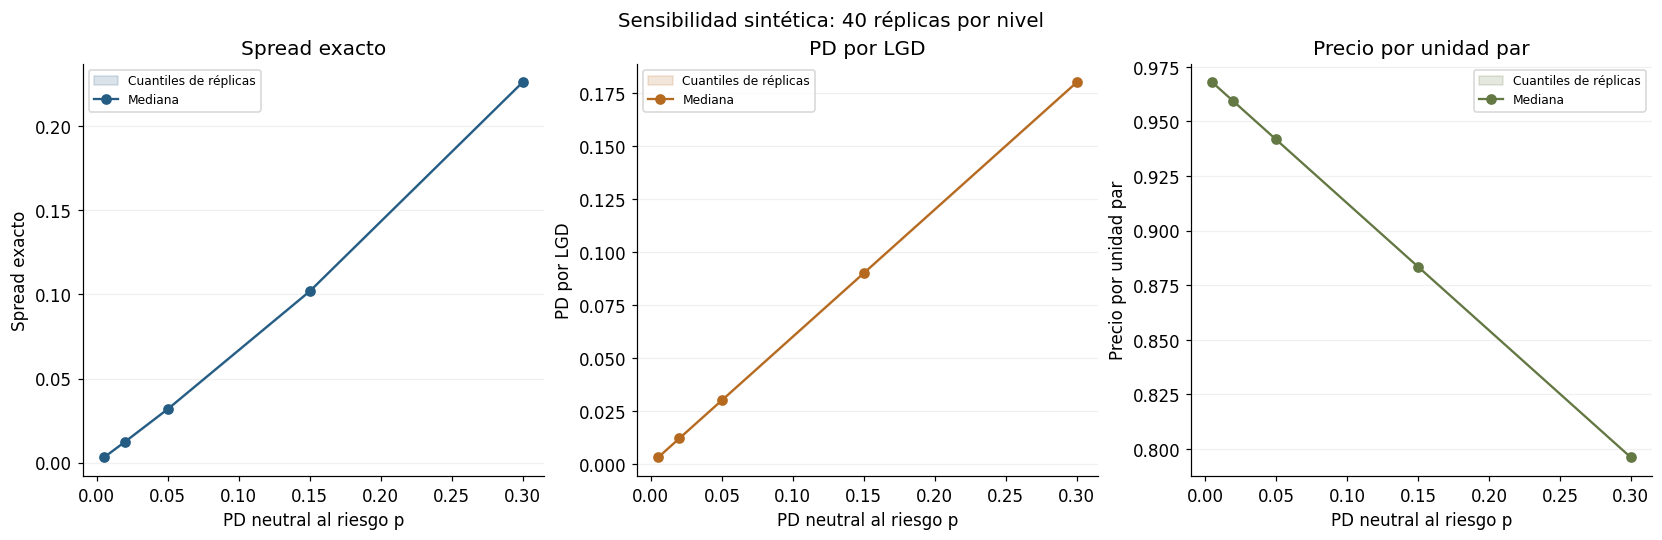

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('PD neutral al riesgo p',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Spread exacto: mediana 0.0030993 en nivel 0.005; 0.226098 en nivel 0.3.
  Último escenario: cuantiles [0.226098, 0.226098], media 0.226098, error MC de la media 0.
PD por LGD: mediana 0.003 en nivel 0.005; 0.18 en nivel 0.3.
  Último escenario: cuantiles [0.18, 0.18], media 0.18, error MC de la media 0.
Precio por unidad par: mediana 0.967961 en nivel 0.005; 0.796117 en nivel 0.3.
  Último escenario: cuantiles [0.796117, 0.796117], media 0.796117, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

No se interpreta el spread como PD física. Múltiples vencimientos, cupones y timing de recuperación requieren otra valuación.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.